# 02 — Feature engineering

Builds one modelling table (`data/processed/model_table.parquet`): one row per `SK_ID_CURR`, labelled
applicants from `application_train` only, with `TARGET`. All logic lives in `src/features.py`:

| Block | Function | Prefix |
|---|---|---|
| Application ratios | `add_application_ratios` | — |
| Credit Bureau aggregates | `bureau_features` | `BUR_` |
| Previous Home Credit applications | `previous_features` | `PREV_` |
| Instalment repayment behaviour | `installment_features` | `INST_` |
| History flags | `add_history_flags` | `HAS_` |

Side tables are aggregated by `SK_ID_CURR` first and then left-joined. Every aggregate summarises only the
applicant's own rows (nothing is learned across applicants), so building the table before the train/holdout
split in notebook 03 does not leak information.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.cleaning import clean_application
from src.config import ID, PROCESSED_DIR, TARGET
from src.eda import binned_rate_table, default_rate_table
from src.features import (add_application_ratios, build_model_table, bureau_features, installment_features,
                          load_side_tables, previous_features)
from src.plotting import plot_rate_bars, savefig, set_style

set_style()
pd.set_option("display.max_columns", 60, "display.width", 160)
RATE_FMT = {"applicants": "{:,}", "share": "{:.1%}", "defaults": "{:,}", "default_rate": "{:.2%}"}

## 0. Load and clean the application table, load side tables

In [2]:
app = clean_application(pd.read_parquet(PROCESSED_DIR / "application_train.parquet"))
bureau, prev, inst = load_side_tables()
for name, df in [("application_train (cleaned)", app), ("bureau", bureau), ("previous_application", prev),
                 ("installments_payments", inst)]:
    print(f"{name:<28} {df.shape[0]:>12,} rows x {df.shape[1]:>3} cols   "
          f"{df.memory_usage(deep=True).sum() / 1024**2:>7.1f} MB")

application_train (cleaned)       307,507 rows x 125 cols      98.0 MB
bureau                          1,716,428 rows x  17 cols      85.1 MB
previous_application            1,670,214 rows x  37 cols     146.5 MB
installments_payments          13,605,401 rows x   8 cols     389.3 MB


## 1. Application ratios
`safe_div` returns NaN (never inf) when the denominator is 0 or missing. `EXT_SOURCE_MEAN` averages the
available scores; `EXT_SOURCE_STD` is NaN when fewer than two scores are present.

In [3]:
ratio_cols = ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM", "GOODS_CREDIT_RATIO",
              "EMPLOYED_TO_AGE", "INCOME_PER_FAMILY_MEMBER", "EXT_SOURCE_MEAN", "EXT_SOURCE_STD"]
ratios = add_application_ratios(app)[ratio_cols + [TARGET]]
summary = ratios[ratio_cols].describe().T[["count", "mean", "50%", "min", "max"]]
summary.insert(1, "n_missing", len(ratios) - summary["count"])
summary["corr_with_TARGET"] = ratios[ratio_cols].astype("float64").corrwith(ratios[TARGET].astype("float64"))
print("inf values in ratio columns:", int(np.isinf(ratios[ratio_cols].to_numpy(dtype="float64")).sum()))
display(summary.round(4))

inf values in ratio columns: 0


,count,n_missing,mean,50%,min,max,corr_with_TARGET
CREDIT_INCOME_RATIO,307507.0,0.0,3.9576,3.2651,0.0048,8.473680e+01,-0.0077
ANNUITY_INCOME_RATIO,307495.0,12.0,0.1809,0.1628,0.0002,1.876000e+00,0.0143
CREDIT_TERM,307495.0,12.0,0.0537,0.0500,0.0221,1.244000e-01,0.0127
GOODS_CREDIT_RATIO,307229.0,278.0,0.9007,0.8938,0.1667,6.666700e+00,-0.0654
EMPLOYED_TO_AGE,252133.0,55374.0,0.1569,0.1187,0.0000,7.288000e-01,-0.0680
INCOME_PER_FAMILY_MEMBER,307505.0,2.0,93106.0781,75000.0000,2812.5000,3.900000e+07,-0.0066
EXT_SOURCE_MEAN,307335.0,172.0,0.5093,0.5245,0.0000,8.789000e-01,-0.2221
EXT_SOURCE_STD,270598.0,36909.0,0.1512,0.1360,0.0000,6.519000e-01,0.0477


## 2. Credit Bureau aggregates (`BUR_`)

In [4]:
bur_agg = bureau_features(bureau)
print("bureau aggregates:", bur_agg.shape, "| one row per SK_ID_CURR:", bur_agg[ID].is_unique)
display(bur_agg.drop(columns=ID).describe().T[["count", "mean", "50%", "min", "max"]].round(3))

bureau aggregates: (305811, 11) | one row per SK_ID_CURR: True


,count,mean,50%,min,max
BUR_LOAN_COUNT,305811.0,5.613,4.000,1.000,1.160000e+02
BUR_ACTIVE_COUNT,305811.0,2.062,2.000,0.000,3.200000e+01
BUR_CREDIT_SUM_SUM,305809.0,1992479.250,978831.000,0.000,1.017958e+09
BUR_CREDIT_SUM_MEAN,305809.0,380739.781,197297.250,0.000,1.980724e+08
BUR_DEBT_SUM,297439.0,672319.875,189747.000,-6981558.500,3.344983e+08
BUR_OVERDUE_SUM,305811.0,212.793,0.000,0.000,3.756681e+06
BUR_MAX_DAY_OVERDUE,305811.0,4.437,0.000,0.000,2.792000e+03
BUR_DAYS_CREDIT_MEAN,305811.0,-1083.802,-1052.500,-2922.000,0.000000e+00
BUR_ACTIVE_SHARE,305811.0,0.410,0.375,0.000,1.000000e+00
BUR_DEBT_CREDIT_RATIO,296292.0,0.290,0.225,-175.289,7.789000e+00


## 3. Previous application aggregates (`PREV_`)
`PREV_DAYS_SINCE_LAST_DECISION` = −max(`DAYS_DECISION`), i.e. days between the most recent previous decision
and the current application.

In [5]:
prev_agg = previous_features(prev)
print("previous-application aggregates:", prev_agg.shape, "| one row per SK_ID_CURR:", prev_agg[ID].is_unique)
print(f"previous applications with AMT_CREDIT == 0 (ratio set to NaN): {int((prev['AMT_CREDIT'] == 0).sum()):,}")
display(prev_agg.drop(columns=ID).describe().T[["count", "mean", "50%", "min", "max"]].round(3))

previous-application aggregates: (338857, 10) | one row per SK_ID_CURR: True
previous applications with AMT_CREDIT == 0 (ratio set to NaN): 336,768


,count,mean,50%,min,max
PREV_APP_COUNT,338857.0,4.929,4.000,1.0,77.0
PREV_APPROVED_COUNT,338857.0,3.060,3.000,0.0,27.0
PREV_REFUSED_COUNT,338857.0,0.858,0.000,0.0,68.0
PREV_AMT_APPLICATION_MEAN,338857.0,154468.281,106834.500,0.0,4050000.0
PREV_AMT_CREDIT_MEAN,338857.0,170331.844,118165.500,0.0,4050000.0
PREV_APP_CREDIT_RATIO_MEAN,338605.0,0.970,0.971,0.0,10.0
PREV_DAYS_SINCE_LAST_DECISION,338857.0,481.489,304.000,1.0,2922.0
PREV_APPROVED_SHARE,338857.0,0.744,0.778,0.0,1.0
PREV_REFUSED_SHARE,338857.0,0.111,0.000,0.0,1.0


## 4. Instalment aggregates (`INST_`)

The raw table has one row per *payment*, and an instalment paid in several parts appears in several rows.
The check below shows why partial payments are combined into one row per instalment before computing
underpayment.

In [6]:
pay = inst["AMT_PAYMENT"].astype("float64")
due = inst["AMT_INSTALMENT"].astype("float64")
row_underpaid = (pay < 0.999 * due).mean()
keys = [ID, "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
per_instalment = (inst.assign(AMT_PAYMENT=pay, AMT_INSTALMENT=due)
                  .groupby(keys, sort=False)
                  .agg(due=("AMT_INSTALMENT", "max"), paid=("AMT_PAYMENT", "sum"), n_rows=("AMT_PAYMENT", "size")))
inst_ratio = per_instalment["paid"] / per_instalment["due"].where(per_instalment["due"] != 0)
print(f"payment rows: {len(inst):,} | distinct instalments: {len(per_instalment):,} | "
      f"instalments paid in >1 part: {int((per_instalment['n_rows'] > 1).sum()):,}")
print(f"row level: payment < instalment in {row_underpaid:.2%} of rows")
print(f"instalment level (parts summed): total paid < instalment in {(inst_ratio < 0.999).mean():.4%} of instalments")
del pay, due, per_instalment, inst_ratio

payment rows: 13,605,401 | distinct instalments: 12,951,918 | instalments paid in >1 part: 640,905
row level: payment < instalment in 8.90% of rows
instalment level (parts summed): total paid < instalment in 0.0426% of instalments


In [7]:
inst_agg = installment_features(inst)
print("instalment aggregates:", inst_agg.shape, "| one row per SK_ID_CURR:", inst_agg[ID].is_unique)
display(inst_agg.drop(columns=ID).describe().T[["count", "mean", "50%", "min", "max"]].round(4))

instalment aggregates: (339587, 9) | one row per SK_ID_CURR: True


,count,mean,50%,min,max
INST_COUNT,339587.0,38.1402,24.0000,1.0000,336.0000
INST_LATE_SHARE,339578.0,0.0843,0.0179,0.0000,1.0000
INST_DAYS_LATE_MEAN,339578.0,1.2252,0.0357,0.0000,2813.0000
INST_DAYS_LATE_MAX,339578.0,17.8441,1.0000,0.0000,2884.0000
INST_PAYMENT_RATIO_MEAN,339575.0,1.4182,1.0000,0.5122,9189.3174
INST_PAYMENT_RATIO_MIN,339575.0,0.9961,1.0000,0.0000,1.9695
INST_UNDERPAID_SHARE,339575.0,0.0003,0.0000,0.0000,1.0000
INST_PARTIAL_PAYMENT_SHARE,339587.0,0.0505,0.0000,0.0000,1.0000


**Insight:** Combining partial payments matters. 8.90% of payment rows are smaller than the instalment, but once
the parts of the same instalment are summed only 0.0426% of instalments are actually underpaid. As a result
`INST_UNDERPAID_SHARE` is almost always 0 (mean 0.0003). The extra feature `INST_PARTIAL_PAYMENT_SHARE` (share of
instalments paid in more than one part, mean 0.0505) keeps the behaviour that row-level "underpayment" was really
measuring. On average applicants were late on 8.43% of their instalments (median 1.79%).

## 5. Join everything onto the cleaned application table

In [8]:
model_table = build_model_table(app, bur_agg, prev_agg, inst_agg)
assert model_table[ID].is_unique and len(model_table) == len(app)
assert model_table[TARGET].notna().all()

print("model table shape:", model_table.shape)
print("feature columns (excluding SK_ID_CURR, TARGET):", model_table.shape[1] - 2)
display(model_table.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("n_columns"))
print(f"memory: {model_table.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

coverage = pd.DataFrame({
    "applicants_without_history": [int((model_table[c] == 0).sum()) for c in
                                   ["HAS_BUREAU_HISTORY", "HAS_PREV_APPLICATION", "HAS_INSTALLMENT_HISTORY"]],
}, index=["no bureau history", "no previous application", "no instalment history"])
coverage["pct_of_applicants"] = coverage["applicants_without_history"] / len(model_table) * 100
coverage["default_rate"] = [model_table.loc[model_table[c] == 0, TARGET].mean() for c in
                            ["HAS_BUREAU_HISTORY", "HAS_PREV_APPLICATION", "HAS_INSTALLMENT_HISTORY"]]
display(coverage.style.format({"applicants_without_history": "{:,}", "pct_of_applicants": "{:.2f}%",
                               "default_rate": "{:.2%}"}))
no_bureau = model_table["HAS_BUREAU_HISTORY"] == 0
print(f"among the {int(no_bureau.sum()):,} applicants without bureau history: "
      f"{model_table.loc[no_bureau, 'HAS_PREV_APPLICATION'].mean():.2%} have a previous application, "
      f"{model_table.loc[no_bureau, 'HAS_INSTALLMENT_HISTORY'].mean():.2%} have instalment history")

model table shape: (307507, 163)
feature columns (excluding SK_ID_CURR, TARGET): 161


,n_columns
dtype,
float32,97
int8,41
category,16
int32,7
int16,2


memory: 139.9 MB


,applicants_without_history,pct_of_applicants,default_rate
no bureau history,"44,020",14.32%,10.12%
no previous application,"16,454",5.35%,5.96%
no instalment history,"15,868",5.16%,5.98%


among the 44,020 applicants without bureau history: 94.39% have a previous application, 94.59% have instalment history


In [9]:
out_path = PROCESSED_DIR / "model_table.parquet"
model_table.to_parquet(out_path, index=False)
print(f"saved {out_path.relative_to(ROOT).as_posix()} ({out_path.stat().st_size / 1024**2:.1f} MB)")

saved data/processed/model_table.parquet (45.0 MB)


**Insight:** The model table has 307,507 rows (one per applicant) and 161 feature columns (163 with `SK_ID_CURR`
and `TARGET`), 139.9 MB in memory and 45.0 MB on disk. 14.32% of applicants have no bureau history, 5.35% no
previous application and 5.16% no instalment history. Crucially for the thin-file question, 94.39% of applicants
without bureau history have a previous Home Credit application and 94.59% have instalment history, so behavioural
alternative data exists for nearly all of them.

## 6. Default rate by engineered features

### 6a. Share of late instalments (`INST_LATE_SHARE`)

,applicants,share,defaults,default_rate
LATE_BAND,,,,
0 (never late),"136,635",44.4%,"9,292",6.80%
0–5%,"38,489",12.5%,"2,648",6.88%
5–10%,"34,204",11.1%,"2,990",8.74%
10–20%,"38,399",12.5%,"3,724",9.70%
20–50%,"37,217",12.1%,"4,189",11.26%
>50%,"6,687",2.2%,"1,032",15.43%
No instalment data,"15,876",5.2%,950,5.98%


saved reports/figures/13_default_rate_by_inst_late_share.png


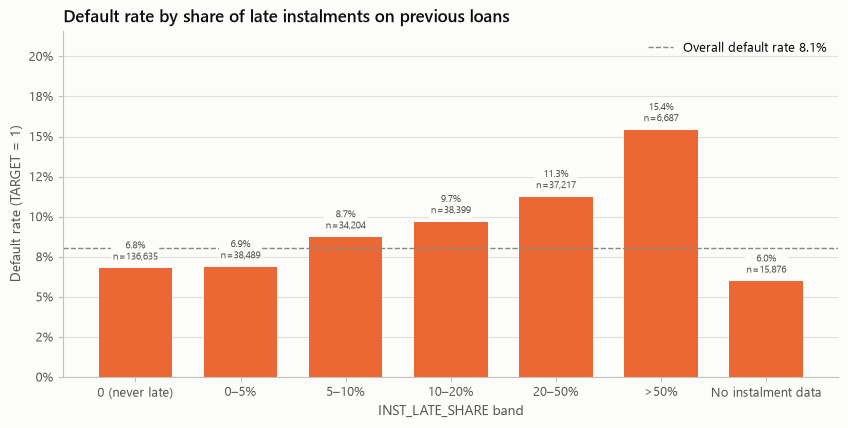

In [10]:
overall_rate = model_table[TARGET].mean()
late_bins = [-0.001, 0, 0.05, 0.10, 0.20, 0.50, 1.0]
late_labels = ["0 (never late)", "0–5%", "5–10%", "10–20%", "20–50%", ">50%"]
late_band = pd.cut(model_table["INST_LATE_SHARE"], bins=late_bins, labels=late_labels)
late_table = default_rate_table(model_table.assign(LATE_BAND=late_band), "LATE_BAND",
                                missing_label="No instalment data")
display(late_table.style.format(RATE_FMT))

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_rate_bars(late_table, ax, "Default rate by share of late instalments on previous loans",
               "INST_LATE_SHARE band", overall_rate=overall_rate, horizontal=False)
savefig(fig, "13_default_rate_by_inst_late_share.png")
plt.show()

**Insight:** Repayment behaviour on earlier Home Credit loans is a strong alternative-data signal. Default rises
steadily from 6.80% for applicants who were never late (44.4% of applicants) to 9.70% at 10–20% late instalments,
11.26% at 20–50% and 15.43% above 50%. The 15,876 applicants without instalment data (15,868 with no instalment
rows plus 8 whose instalments have no recorded payment) default at only 5.98%.

### 6b. Share of refused previous applications (`PREV_REFUSED_SHARE`)

,applicants,share,defaults,default_rate
REFUSED_BAND,,,,
0 (none refused),"190,763",62.0%,"13,493",7.07%
0–25%,"47,397",15.4%,"3,846",8.11%
25–50%,"41,736",13.6%,"4,729",11.33%
>50%,"11,157",3.6%,"1,777",15.93%
No previous application,"16,454",5.4%,980,5.96%


saved reports/figures/14_default_rate_by_prev_refused_share.png


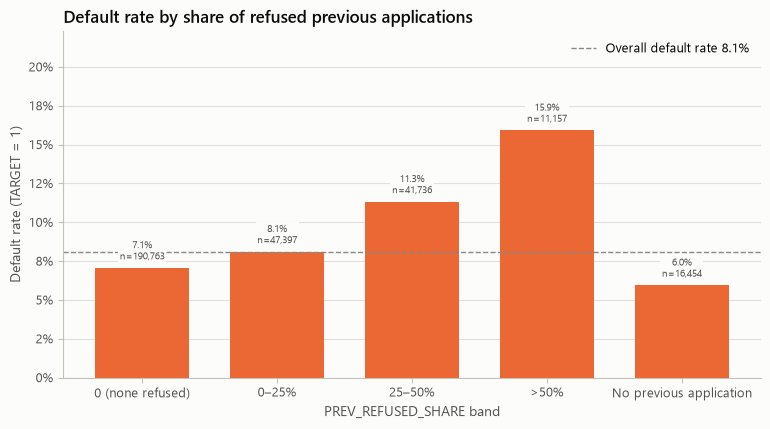

In [11]:
ref_bins = [-0.001, 0, 0.25, 0.50, 1.0]
ref_labels = ["0 (none refused)", "0–25%", "25–50%", ">50%"]
ref_band = pd.cut(model_table["PREV_REFUSED_SHARE"], bins=ref_bins, labels=ref_labels)
ref_table = default_rate_table(model_table.assign(REFUSED_BAND=ref_band), "REFUSED_BAND",
                               missing_label="No previous application")
display(ref_table.style.format(RATE_FMT))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_rate_bars(ref_table, ax, "Default rate by share of refused previous applications",
               "PREV_REFUSED_SHARE band", overall_rate=overall_rate, horizontal=False)
savefig(fig, "14_default_rate_by_prev_refused_share.png")
plt.show()

**Insight:** Past refusals are a warning sign. Applicants with none of their previous applications refused default
at 7.07%, compared with 11.33% when 25–50% were refused and 15.93% when more than half were refused (11,157
applicants). Applicants with no previous application default at 5.96%.

### 6c. Average external score (`EXT_SOURCE_MEAN`) deciles

,applicants,share,defaults,default_rate
EXT_SOURCE_MEAN,,,,
"(-0.00099406, 0.304]","30,734",10.0%,"7,048",22.93%
"(0.304, 0.384]","30,733",10.0%,"4,461",14.52%
"(0.384, 0.439]","30,734",10.0%,"3,228",10.50%
"(0.439, 0.484]","30,734",10.0%,"2,494",8.11%
"(0.484, 0.525]","30,734",10.0%,"1,975",6.43%
"(0.525, 0.564]","30,732",10.0%,"1,656",5.39%
"(0.564, 0.603]","30,734",10.0%,"1,277",4.16%
"(0.603, 0.644]","30,733",10.0%,"1,148",3.74%
"(0.644, 0.693]","30,733",10.0%,897,2.92%


applicants with no EXT_SOURCE score at all: 172
saved reports/figures/15_default_rate_by_ext_source_mean_decile.png


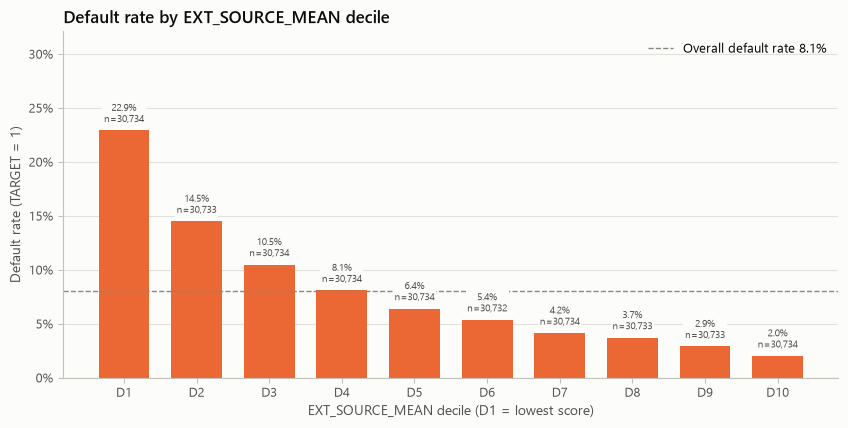

In [12]:
ext_table = binned_rate_table(model_table, "EXT_SOURCE_MEAN", q=10)
display(ext_table.style.format(RATE_FMT))
print(f"applicants with no EXT_SOURCE score at all: {int(model_table['EXT_SOURCE_MEAN'].isna().sum())}")

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_rate_bars(ext_table.set_axis([f"D{i}" for i in range(1, len(ext_table) + 1)]), ax,
               "Default rate by EXT_SOURCE_MEAN decile", "EXT_SOURCE_MEAN decile (D1 = lowest score)",
               overall_rate=overall_rate, horizontal=False)
savefig(fig, "15_default_rate_by_ext_source_mean_decile.png")
plt.show()

**Insight:** Averaging the three external scores gives the sharpest risk ranking in the data. The default rate falls
from 22.93% in the lowest `EXT_SOURCE_MEAN` decile to 2.04% in the highest, and its correlation with TARGET
(−0.2221) is stronger than that of any single EXT_SOURCE column (strongest: −0.1789). Only 172 applicants have no
external score at all.

### 6d. Engineered features ranked by |correlation| with TARGET

In [13]:
engineered = ratio_cols + [c for c in model_table.columns if c.startswith(("BUR_", "PREV_", "INST_", "HAS_"))]
eng_corr = model_table[engineered].astype("float64").corrwith(model_table[TARGET].astype("float64"))
eng_rank = pd.DataFrame({"corr_with_TARGET": eng_corr,
                         "pct_missing": model_table[engineered].isna().mean() * 100})
eng_rank = eng_rank.reindex(eng_corr.abs().sort_values(ascending=False).index)
display(eng_rank.head(15).round(4))

,corr_with_TARGET,pct_missing
EXT_SOURCE_MEAN,-0.2221,0.0559
BUR_DAYS_CREDIT_MEAN,0.0897,14.3151
PREV_REFUSED_SHARE,0.0777,5.3508
BUR_ACTIVE_SHARE,0.0774,14.3151
INST_LATE_SHARE,0.0705,5.1628
EMPLOYED_TO_AGE,-0.0680,18.0074
GOODS_CREDIT_RATIO,-0.0654,0.0904
PREV_REFUSED_COUNT,0.0648,0.0000
PREV_APPROVED_SHARE,-0.0635,5.3508
BUR_DEBT_CREDIT_RATIO,0.0606,17.0263


**Insight:** After `EXT_SOURCE_MEAN`, the strongest engineered signals come from all three side tables:
`BUR_DAYS_CREDIT_MEAN` (r = 0.0897; more recent bureau credits on average means higher risk), `PREV_REFUSED_SHARE`
(0.0777), `BUR_ACTIVE_SHARE` (0.0774) and `INST_LATE_SHARE` (0.0705). The affordability ratios are weak linearly
(e.g. `CREDIT_INCOME_RATIO` r = −0.0077), consistent with the non-monotonic pattern in notebook 01. Correlation
only measures linear association, so each feature's real value is judged by the models in notebook 03.

## 7. Supporting analysis: why do first-time Home Credit customers default less?

Notebook 01 found that applicants without a previous Home Credit application default *less* often (5.96% vs 8.19%).
This section profiles them with the engineered features (used in report section 5).

In [14]:
first_time = model_table["HAS_PREV_APPLICATION"] == 0
returning = ~first_time
ft_bureau = first_time & (model_table["HAS_BUREAU_HISTORY"] == 1)
ft_none = first_time & (model_table["HAS_BUREAU_HISTORY"] == 0)
revolving = model_table["NAME_CONTRACT_TYPE"] == "Revolving loans"
print(f"first-time applicants: {int(first_time.sum()):,}; with a Credit Bureau record: "
      f"{model_table.loc[first_time, 'HAS_BUREAU_HISTORY'].mean():.2%}")
print(f"default rate, first-time with bureau record: {model_table.loc[ft_bureau, TARGET].mean():.2%} "
      f"(n={int(ft_bureau.sum()):,}); first-time without: {model_table.loc[ft_none, TARGET].mean():.2%} "
      f"(n={int(ft_none.sum()):,})")
print(f"revolving-loan share: first-time {revolving[first_time].mean():.2%} vs returning {revolving[returning].mean():.2%}")
print(f"median income: first-time {model_table.loc[first_time, 'AMT_INCOME_TOTAL'].median():,.0f} vs returning "
      f"{model_table.loc[returning, 'AMT_INCOME_TOTAL'].median():,.0f}")

prev_bins = pd.cut(model_table["PREV_APP_COUNT"], [-1, 0, 1, 2, 4, 9, np.inf], labels=["0", "1", "2", "3-4", "5-9", "10+"])
display(default_rate_table(model_table.assign(PREV_APP_BIN=prev_bins), "PREV_APP_BIN").style.format(RATE_FMT))

refused_bins = pd.cut(model_table.loc[returning, "PREV_REFUSED_SHARE"], [-0.01, 0, 0.5, 1.0],
                      labels=["none refused", "up to 50% refused", "more than 50% refused"])
display(default_rate_table(model_table[returning].assign(REFUSED_BIN=refused_bins), "REFUSED_BIN")
        .style.format(RATE_FMT))

first-time applicants: 16,454; with a Credit Bureau record: 84.99%
default rate, first-time with bureau record: 5.72% (n=13,984); first-time without: 7.29% (n=2,470)
revolving-loan share: first-time 17.56% vs returning 9.07%
median income: first-time 157,500 vs returning 144,000


,applicants,share,defaults,default_rate
PREV_APP_BIN,,,,
0,"16,454",5.4%,980,5.96%
1,"52,533",17.1%,"4,400",8.38%
2,"45,799",14.9%,"3,599",7.86%
3-4,"72,935",23.7%,"5,616",7.70%
5-9,"86,647",28.2%,"7,021",8.10%
10+,"33,139",10.8%,"3,209",9.68%


,applicants,share,defaults,default_rate
REFUSED_BIN,,,,
none refused,"190,763",65.5%,"13,493",7.07%
up to 50% refused,"89,133",30.6%,"8,575",9.62%
more than 50% refused,"11,157",3.8%,"1,777",15.93%


**Insight:** The lower default rate of first-time customers looks like selection, not a benefit of being new.
84.99% of them have a Credit Bureau record (established borrowers choosing Home Credit for one purchase; 17.56% take
revolving loans vs 9.07% of returning customers, and their median income is higher, 157,500 vs 144,000). The 2,470
first-time applicants without a bureau record default at 7.29%, close to the overall rate. Coming back is informative
in itself: the default rate is 5.96% with no previous application, 8.38% with one, about 7.7–8.1% for two to nine and
9.68% for ten or more. Among returning customers it rises from 7.07% (no earlier refusal) to 15.93% (more than half
refused), consistent with riskier applicants re-applying after a rejection. These are associations, not causal
effects.